# 5. Topic clusters with K-means and cluster-routed classification (WELFake)

Published classifiers reach 96–99% accuracy on WELFake. Part of the project asks **how much of that comes from
shortcuts** instead of an understanding of fake news. Notebook 04 handles near-duplicate copies of the same story.
This notebook handles **topic overlap**: the four source datasets cover different subjects in different proportions,
so a model may learn "this topic is usually fake" instead of how fake news is written.

K-means groups the articles into topics without ever seeing a label. We use the clusters in three ways:

1. **To measure the topic shortcut:** how well does the cluster alone predict the label?
2. **Cluster routing (Model C):** one logistic regression per cluster, so each classifier specialises in one topic.
   Does that beat a single global classifier on the same features?
3. **Unseen topics:** the `cluster` split holds out whole topic clusters (README, "The cluster split"). How much do
   the models lose on topics that never occur in training?

The main clusters are built on the **sentence embeddings** (all-MiniLM-L6-v2, notebook 03), as in the project plan;
clusters on **TF-IDF + SVD** are kept as a comparison. The classifiers always use TF-IDF. Code:
`fake_news.models.model_c`; `scripts/run_model_c.py` tunes the model and writes the tables in `reports/model_c/`.
Everything is fitted on **train** only and scored on **val**; test is not used here. Main split: `grouped`.

In [1]:
%load_ext autoreload
%autoreload 2

import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import davies_bouldin_score, roc_auc_score, silhouette_score

from fake_news import config
from fake_news.data import load_dataset
from fake_news.evaluation import evaluate
from fake_news.models import model_c as mc
from fake_news.similarity.plots import BARS, FAKE, INK2, MUTED, REAL, save, use_style

use_style()
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 220)
REPORTS = config.PROJECT_ROOT / "reports" / "model_c"
SPACES = {"embeddings": "", "svd": "__svd"}            # cluster space -> report file tag
SPACE_COLOR = {"embeddings": INK2, "svd": BARS}       # neutral colours: blue/orange are reserved for real/fake
SPACE_MARKER = {"embeddings": "o", "svd": "s"}

df = load_dataset("grouped", columns=["content"])
train, val = (df[df.split == s].reset_index(drop=True) for s in ("train", "val"))
ytr, yva = train.is_fake.to_numpy(), val.is_fake.to_numpy()
print(f"train {len(train):,} ({ytr.mean():.1%} fake)   val {len(val):,} ({yva.mean():.1%} fake)")

train 43,766 (44.4% fake)   val 9,380 (44.4% fake)


## 1. Features: TF-IDF for the classifiers, two spaces for the clusters

- **TF-IDF** (for the classifiers, and the basis of the SVD space). One column per word: up to 50,000 words that appear
  in at least 5 training articles and in at most half of them, English stop words removed. A word's weight grows with
  how often it appears in the article (sub-linear, $1 + \log tf$) and with how rare it is across articles (IDF). The
  matrix is *sparse*: an article uses only a few hundred words.
- **Sentence embeddings** (main cluster space). 384 numbers per article from a pretrained Sentence-BERT model that
  reads the title and the opening of the article (256 word pieces). Texts with similar *meaning* get similar vectors,
  even with different words. Nothing is fitted on our data, so there is no leakage.
- **TF-IDF + SVD** (comparison). `TruncatedSVD` compresses the TF-IDF matrix to 200 dense dimensions; each dimension
  is a pattern of words that appear together (LSA "topics").

Both cluster spaces are L2-normalised: on unit vectors, Euclidean K-means groups by cosine similarity. The cluster
vectors only decide the cluster; the TF-IDF words decide fake or real.

In [2]:
t0 = time.perf_counter()
feats = mc.TopicFeatures()
Xtr, Str = feats.fit_transform(train.content)
Xva, Sva = feats.transform(val.content)
Z = {"embeddings": (mc.embedding_vectors(train.doc_id), mc.embedding_vectors(val.doc_id)), "svd": (Str, Sva)}
terms = feats.tfidf.get_feature_names_out()
print(f"TF-IDF: {Xtr.shape[0]:,} x {Xtr.shape[1]:,}, {Xtr.nnz / Xtr.shape[0]:.0f} non-zero words per article "
      f"({100 * Xtr.nnz / np.prod(Xtr.shape):.2f}% of the matrix)")
print(f"embeddings: {Z['embeddings'][0].shape[1]} dims;  SVD: {feats.n_components} dims keep "
      f"{feats.explained_variance:.1%} of the TF-IDF variance  ({time.perf_counter() - t0:.0f} s)")
pd.DataFrame([{"SVD dimension": i,
               "+ words": ", ".join(terms[np.argsort(-feats.svd.components_[i])[:7]]),
               "- words": ", ".join(terms[np.argsort(feats.svd.components_[i])[:7]])} for i in range(1, 6)]
             ).set_index("SVD dimension")

TF-IDF: 43,766 x 47,937, 188 non-zero words per article (0.39% of the matrix)
embeddings: 384 dims;  SVD: 200 dims keep 15.5% of the TF-IDF variance  (10 s)


,+ words,- words
SVD dimension,,
1,"clinton, trump, hillary, republican, donald, campaign, republicans","minister, military, korea, syria, united, government, north"
2,"trump, house, senate, republican, russia, committee, republicans","police, people, like, man, just, black, life"
3,"russia, russian, clinton, trump, hillary, fbi, comey","tax, obamacare, senate, republicans, percent, health, legislation"
4,"trump, korea, north, nuclear, donald, china, korean","fbi, investigation, comey, department, federal, court, justice"
5,"korea, trump, north, house, nuclear, china, white","clinton, party, election, voters, vote, hillary, democratic"


Each SVD dimension is a contrast between two themes (the US election vs international affairs, the Russia/FBI story
vs legislation, ...). SVD keeps only ~15% of the TF-IDF variance; that is expected for text, where most of the
variance is words specific to a single article, while clustering needs the shared topic structure.

## 2. K-means and the choice of K

**Lloyd's algorithm** (week 6): choose K centroids, assign every article to its nearest centroid, move every centroid to
the mean of its articles, repeat until no article changes cluster. We use **k-means++** initialisation (each new
starting centroid far from the previous ones) and keep the best of 10 runs (`n_init=10`). K-means minimises the
**inertia**, the total squared distance of the articles to their centroids. Criteria for K = 2 … 64:

- **Davies–Bouldin index** (week 6): for each cluster, the worst ratio (spread of the two clusters) / (distance between
  their centroids), averaged. Lower = tighter, better separated clusters.
- **Silhouette** (5,000 sampled training articles): $(b - a) / \max(a, b)$ with $a$ the mean distance to the own
  cluster and $b$ to the nearest other one. Near 1 = clearly placed, near 0 = on a border.
- **Cluster-only val AUC** (section 4): how much of the label the cluster alone reveals.

For the classifier the deciding criterion is downstream: the val ROC-AUC of Model C (section 5).

In [3]:
K_LIST = [2, 4, 8, 16, 32, 64]
sample = np.random.default_rng(config.SEED).choice(len(train), 5000, replace=False)
kms, rows = {}, []
for space, (Ztr, Zva) in Z.items():
    for k in K_LIST:
        kms[space, k] = km = mc.fit_kmeans(Ztr, k)
        sizes = np.bincount(km.labels_, minlength=k)
        share = np.array([ytr[km.labels_ == j].mean() for j in range(k)])
        rows.append({"space": space, "K": k, "davies_bouldin": davies_bouldin_score(Ztr, km.labels_),
                     "silhouette": silhouette_score(Ztr[sample], km.labels_[sample]),
                     "largest cluster": sizes.max() / len(Ztr), "smallest cluster": sizes.min(),
                     "fake share range": f"{share.min():.0%} - {share.max():.0%}",
                     "cluster-only val AUC": roc_auc_score(yva, mc.topic_only_proba(share, km.predict(Zva), ytr.mean()))})
kmetrics = pd.DataFrame(rows).set_index(["space", "K"])
kmetrics.style.format({"davies_bouldin": "{:.2f}", "silhouette": "{:.3f}", "largest cluster": "{:.1%}",
                       "smallest cluster": "{:,}", "cluster-only val AUC": "{:.3f}"})

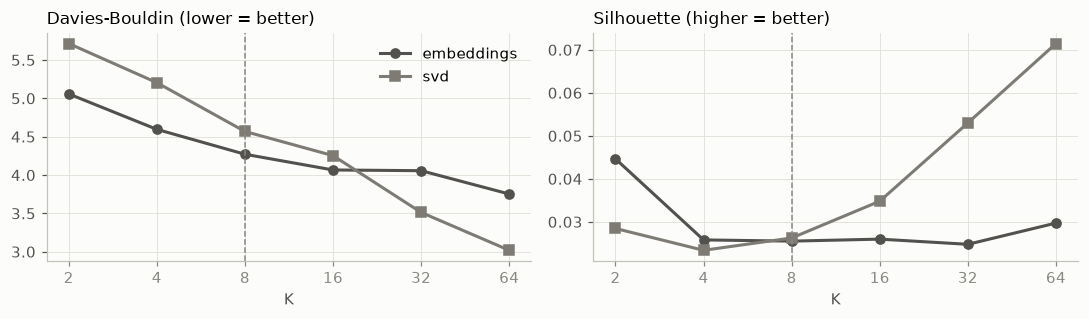

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, col, title in zip(axes, ["davies_bouldin", "silhouette"],
                          ["Davies-Bouldin (lower = better)", "Silhouette (higher = better)"]):
    for space in Z:
        ax.plot(K_LIST, kmetrics.loc[space, col], linestyle="-", marker=SPACE_MARKER[space], color=SPACE_COLOR[space], linewidth=2, label=space)
    ax.axvline(8, color=MUTED, linestyle="--", linewidth=1)
    ax.set_xscale("log", base=2); ax.set_xticks(K_LIST, [str(k) for k in K_LIST]); ax.set_xlabel("K")
    ax.set_title(title)
axes[0].legend()
save(fig, "kmeans_choose_k"); plt.show()

**No clear best K in either space.** Davies–Bouldin keeps improving as K grows, and the silhouette stays low
(around 0.03 for the embeddings, 0.02–0.07 for SVD). Topics in news blend into each other ("Trump + Russia" next to
"Russia + Putin"), so there is no natural number of groups and many articles sit near a border. The clusters are
meaningful (section 3) but **overlapping**, a known limitation of hard K-means assignments (week 6: K-means assumes
compact, well-separated, similarly sized clusters). K is therefore chosen by Model C's val score: **K = 8** in both
spaces (section 5).

## 3. What the clusters are (K = 8)

Embedding centroids cannot be mapped back to words, so a cluster is described by its **characteristic words**: the
words whose mean TF-IDF in the cluster's training articles is furthest above their mean over all training articles.

In [5]:
K = 8
def cluster_table(space):
    km = kms[space, K]
    lab = km.labels_
    top = mc.member_top_terms(Xtr, lab, terms, 9)
    return pd.DataFrame({"cluster": range(K), "train articles": np.bincount(lab, minlength=K),
                         "fake share": [ytr[lab == j].mean() for j in range(K)],
                         "characteristic words": [", ".join(t) for t in top]}).sort_values("fake share", ascending=False)

emb_clusters, svd_clusters = cluster_table("embeddings"), cluster_table("svd")
emb_clusters.style.format({"fake share": "{:.1%}", "train articles": "{:,}"}).hide(axis="index")

cluster,train articles,fake share,characteristic words
1,"5,600",63.9%,"police, black, gun, officers, shooting, man, video, protesters, arrested"
5,"9,917",63.6%,"trump, clinton, hillary, donald, campaign, republican, presidential, candidate, voters"
3,"5,135",59.6%,"fbi, investigation, clinton, comey, emails, russia, intelligence, russian, hillary"
0,"5,621",48.1%,"company, life, water, world, ms, dr, study, food, film"
7,"4,357",27.3%,"islamic, syria, al, forces, syrian, killed, military, iraq, militants"
4,"5,349",24.8%,"senate, tax, obamacare, republicans, republican, house, legislation, healthcare, congress"
2,"4,623",18.6%,"korea, nuclear, north, china, united, russia, sanctions, states, foreign"
6,"3,164",12.8%,"eu, minister, european, parliament, brexit, party, britain, prime, union"


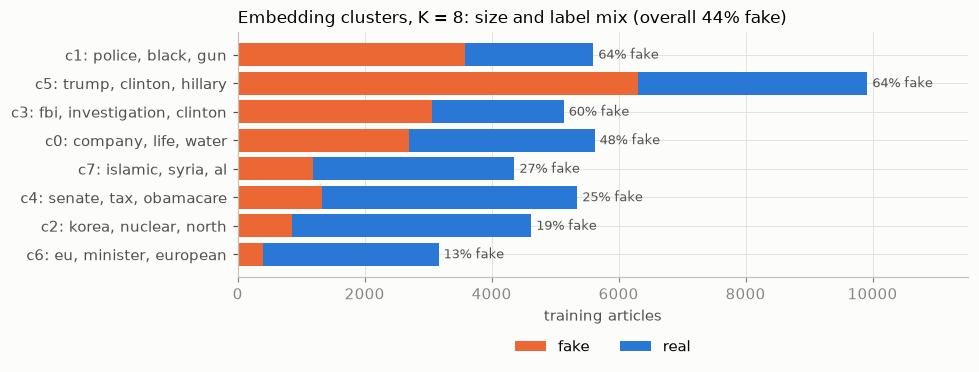

In [6]:
c = emb_clusters.reset_index(drop=True)
names = [", ".join(t.split(", ")[:3]) for t in c["characteristic words"]]
fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(c))[::-1]
n_fake = c["train articles"] * c["fake share"]
ax.barh(y, n_fake, color=FAKE, label="fake")
ax.barh(y, c["train articles"] - n_fake, left=n_fake, color=REAL, label="real")
for yi, (n, s) in zip(y, zip(c["train articles"], c["fake share"])):
    ax.text(n + 80, yi, f"{s:.0%} fake", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(y, [f"c{j}: {nm}" for j, nm in zip(c.cluster, names)])
ax.set_xlim(0, c["train articles"].max() * 1.16)
ax.set_xlabel("training articles"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
ax.set_title(f"Embedding clusters, K = {K}: size and label mix (overall {ytr.mean():.0%} fake)")
save(fig, "kmeans_clusters_fake_share"); plt.show()

The embedding clusters are clean news topics: the 2016 election, the FBI/Clinton-email/Russia story, police and
shootings, Congress and legislation, Syria and Iraq, North Korea and foreign policy, Europe and Brexit, and a general
"science, health and lifestyle" cluster. Their label mix ranges from about **13% fake** (Europe/Brexit) to about
**64% fake** (election, police).

**The comparison with the TF-IDF + SVD clusters is revealing.** Their most fake cluster is a *style*, not a subject:

In [7]:
svd_clusters.head(3).style.format({"fake share": "{:.1%}", "train articles": "{:,}"}).hide(axis="index")

cluster,train articles,fake share,characteristic words
6,"7,782",83.5%,"trump, donald, video, watch, just, know, like, america, twitter"
3,"3,276",60.4%,"fbi, comey, clinton, investigation, emails, russia, russian, intelligence, hillary"
1,"5,895",49.9%,"life, mr, like, world, ms, years, company, school, dr"


*trump, donald, just, like, people, video, watch, know, don*: an informal, opinionated blog tone ("watch this video,
you just don't know…"), about 84% fake. TF-IDF sees every word, including these style words, so its clusters partly
group by **writing style**, which is tied to the source. Cleaning removed explicit source markers but deliberately kept
house style such as "Watch the video below" and "Mr." (cleaning decisions G4 and G8 in `reports/cleaning/DECISIONS.md`).
The embeddings mostly encode what an article is *about*, so their clusters are purer topics. Section 4 measures the
consequence.

## 4. The cluster shortcut: how much does the cluster alone reveal?

A reference predictor that reads nothing but the cluster: P(fake) = fake share of the article's cluster in train.
Its val ROC-AUC measures how much of the label is predictable from the cluster alone (0.5 = nothing, 1 = everything).

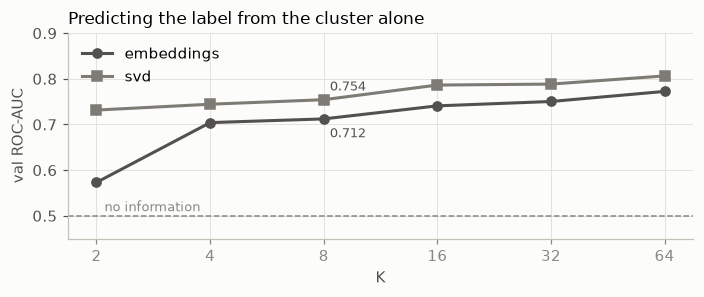

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 2.8))
for space in Z:
    v = kmetrics.loc[space, "cluster-only val AUC"]
    ax.plot(K_LIST, v, linestyle="-", marker=SPACE_MARKER[space], color=SPACE_COLOR[space], linewidth=2, label=space)
    ax.annotate(f"{v.loc[8]:.3f}", (8, v.loc[8]), textcoords="offset points", xytext=(4, -12 if space == "embeddings" else 6),
                fontsize=8.5, color=INK2)
ax.axhline(0.5, color=MUTED, linestyle="--", linewidth=1); ax.text(2.1, 0.51, "no information", color=MUTED, fontsize=8.5)
ax.set_xscale("log", base=2); ax.set_xticks(K_LIST, [str(k) for k in K_LIST]); ax.set_ylim(0.45, 0.9)
ax.set_xlabel("K"); ax.set_ylabel("val ROC-AUC"); ax.legend(loc="upper left")
ax.set_title("Predicting the label from the cluster alone")
save(fig, "kmeans_topic_only_auc"); plt.show()

**The cluster alone predicts the label well above chance**: val ROC-AUC about 0.71 for the embedding clusters and 0.75
for the SVD clusters at K = 8, rising with K (small clusters become almost pure). On WELFake, *what* an article is about
already gives away much of its label: the topic shortcut, measured.

**The SVD clusters reveal more of the label at every K.** They also capture writing style (section 3), and style is
tied to the source. So the "topic" shortcut contains a **style/source component**; the embedding clusters isolate the
topic part more cleanly.

## 5. Model C: cluster routing against a global logistic regression

**Model C** routes each article to its nearest centroid and scores it with that cluster's own logistic regression,
trained on the cluster's training articles with the full TF-IDF features. A cluster with fewer than 200 training
articles or a single class falls back to the global classifier (never needed at K ≤ 32).

The fair comparison is the **global LR**: one logistic regression on all training articles with exactly the same
features (Model C with K = 1, the "no routing" configuration). `scripts/run_model_c.py` tuned K ∈ {8, 16, 32} and
C ∈ {10, 30, 100} on grouped val for each cluster space and kept that setting fixed on the other splits; the global LR is
tuned over the same C values on every split. We read its tables here instead of refitting.

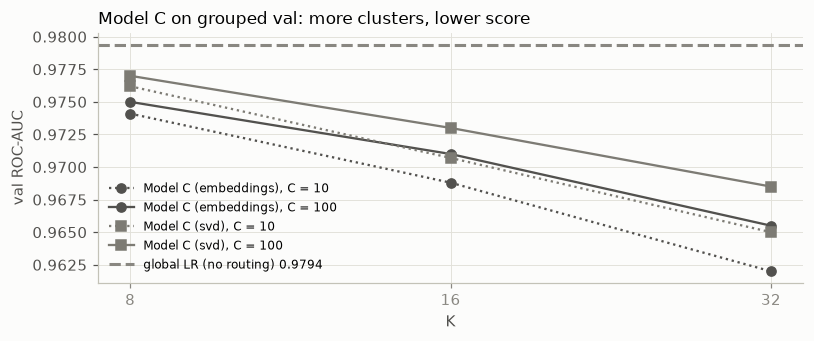

roc_auc                 accuracy                
split                                  random grouped cluster   random grouped cluster
model                                                                                 
Model C (embeddings)                   0.9745  0.9750  0.9619   0.9197  0.9212  0.8944
Model C (svd)                          0.9759  0.9770  0.9692   0.9239  0.9233  0.9082
average global + Model C (embeddings)  0.9795  0.9809  0.9742   0.9322  0.9301  0.9176
average global + Model C (svd)         0.9803  0.9817  0.9763   0.9325  0.9348  0.9230
cluster only (embeddings)              0.7137  0.7116  0.7162   0.6756  0.6743  0.6346
cluster only (svd)                     0.7516  0.7543  0.7655   0.6877  0.6884  0.7250
global LR (no routing)                 0.9776  0.9794  0.9747   0.9281  0.9293  0.9218

In [9]:
summary = {(space, r): json.loads((REPORTS / f"{r}{tag}_summary.json").read_text())
           for space, tag in SPACES.items() for r in ("random", "grouped", "cluster")}

fig, ax = plt.subplots(figsize=(7.5, 3.2))
for space, tag in SPACES.items():
    t = pd.read_csv(REPORTS / f"grouped{tag}_tuning.csv")
    for c_val, ls in zip((10, 100), (":", "-")):
        tc = t[(t.model == "model_c") & (t.c == c_val)]
        ax.plot(tc.k, tc.roc_auc, ls, marker=SPACE_MARKER[space], color=SPACE_COLOR[space], label=f"Model C ({space}), C = {c_val:g}")
best_global = summary["embeddings", "grouped"]["val"]["global_lr"]["roc_auc"]
ax.axhline(best_global, color=MUTED, linewidth=2, linestyle="--", label=f"global LR (no routing) {best_global:.4f}")
ax.set_xscale("log", base=2); ax.set_xticks([8, 16, 32], ["8", "16", "32"])
ax.set_xlabel("K"); ax.set_ylabel("val ROC-AUC"); ax.legend(loc="lower left", fontsize=8)
ax.set_title("Model C on grouped val: more clusters, lower score")
save(fig, "model_c_vs_k"); plt.show()

rows = []
for (space, r), s in summary.items():
    for m in ("model_c", "global_lr", "hybrid_avg", "topic_only"):
        if space == "svd" and m == "global_lr":
            continue                                    # same global LR in both spaces
        name = {"model_c": f"Model C ({space})", "global_lr": "global LR (no routing)",
                "hybrid_avg": f"average global + Model C ({space})", "topic_only": f"cluster only ({space})"}[m]
        rows.append({"model": name, "split": r, "roc_auc": s["val"][m]["roc_auc"], "accuracy": s["val"][m]["accuracy"]})
results = pd.DataFrame(rows).pivot(index="model", columns="split")[[("roc_auc", r) for r in ("random", "grouped", "cluster")]
                                                                    + [("accuracy", r) for r in ("random", "grouped", "cluster")]]
results.round(4)

**Model C does not beat the global LR, in either cluster space.** At the chosen K = 8 it is about 0.002–0.004 ROC-AUC
below on grouped val, and every additional split of the data makes it worse. Each per-cluster classifier learns from
fewer articles (about 5,500 instead of 43,766 at K = 8); this would pay off only if the fake/real signals differed
strongly between topics. They mostly do not: the same words and the same style give fake articles away whatever the
subject. Routing on the SVD clusters is slightly better than on the embedding clusters, plausibly because the SVD
clusters also separate styles, which carry the label (section 3).

**Random vs grouped hardly differs** for these word-based models. Near-duplicate groups cover only a few percent of the
articles, too few to move a classifier that learns from words.

The rows "average global + Model C" are *above* both on random and grouped. Section 7 checks whether that gain is real;
section 8 looks at the `cluster` columns.

## 6. Inside each cluster (embedding clusters, grouped val)

If Model C is worse overall, is it worse in every cluster? The table compares both models on the val articles of each
cluster (global LR at its own best C).

In [10]:
per = pd.read_csv(REPORTS / "grouped_clusters.csv")
per["difference"] = per.val_auc_model_c - per.val_auc_global_lr
per["words"] = per.top_terms.str.split(", ").str[:5].str.join(", ")
per[["cluster", "n_train", "fake_share_train", "n_val", "val_auc_model_c", "val_auc_global_lr", "difference", "words"]] \
    .style.format({"fake_share_train": "{:.1%}", "val_auc_model_c": "{:.4f}", "val_auc_global_lr": "{:.4f}",
                   "difference": "{:+.4f}", "n_train": "{:,}", "n_val": "{:,}"}).hide(axis="index")

cluster,n_train,fake_share_train,n_val,val_auc_model_c,val_auc_global_lr,difference,words
5,"9,913",63.6%,"2,080",0.9694,0.9710,-0.0016,"trump, clinton, hillary, donald, campaign"
0,"5,622",48.1%,"1,168",0.9789,0.9753,+0.0036,"company, life, water, world, ms"
1,"5,598",64.0%,"1,231",0.9480,0.9541,-0.0061,"police, black, gun, officers, shooting"
4,"5,350",24.8%,"1,147",0.9638,0.9759,-0.0121,"senate, tax, obamacare, republicans, republican"
3,"5,138",59.6%,"1,121",0.9747,0.9814,-0.0067,"fbi, investigation, clinton, comey, emails"
2,"4,622",18.6%,993,0.9725,0.9784,-0.0059,"korea, nuclear, north, china, united"
7,"4,359",27.4%,951,0.9761,0.9837,-0.0076,"islamic, syria, al, forces, syrian"
6,"3,164",12.8%,689,0.9876,0.9855,+0.0021,"eu, minister, european, parliament, brexit"


**Model C is worse inside 6 of the 8 clusters**, most clearly in Congress/legislation (−0.012 ROC-AUC) and
Syria/Iraq (−0.008); it is better only in the "science, health and lifestyle" cluster (+0.004) and Europe/Brexit
(+0.002). So the overall gap is mostly a real loss: each specialist learns from about an eighth of the data and misses
signals the global model learns from all articles. (With the TF-IDF + SVD clusters the two models were almost tied
inside each cluster; there, a second effect is visible: the eight classifiers are trained separately, so their
probabilities are on slightly different scales, which costs a little when all articles are ranked together.)

## 7. Does combining help, and is it the topics?

Averaging the global LR and Model C scored higher than either on grouped val. But averaging *any* two models often
helps a little, so we need a **control**: what does averaging give when the second model knows nothing about topics?

- **Average:** global LR (its best C) averaged with Model C (embedding clusters, K = 8).
- **Control 1:** global LR averaged with another global LR (C = 100). Same idea, no clusters.
- **Control 2:** global LR averaged with 8 LRs trained on **random** groups of the same sizes as the clusters, each val
  article routed to a random group. Identical to the average except that the groups are not topics.

The uncertainty comes from a **bootstrap**: the val set is resampled 1,000 times with replacement, and the 95% interval
of the AUC *difference* to the global LR is reported. Each resample compares all models on the same articles.

In [11]:
s_g = summary["embeddings", "grouped"]
c_glob, c_model = s_g["val"]["global_lr"]["c"], s_g["c"]
lab_tr, lab_va = kms["embeddings", K].labels_, kms["embeddings", K].predict(Z["embeddings"][1])
g = mc.fit_global_lr(Xtr, ytr, c_glob)
p_glob = g.predict_proba(Xva)[:, 1]
p_glob2 = mc.fit_global_lr(Xtr, ytr, c_model).predict_proba(Xva)[:, 1]
p_c = mc.fit_cluster_classifiers(Xtr, ytr, lab_tr, c_model, g, k=K).predict_proba(Xva, lab_va)

rng = np.random.default_rng(config.SEED)
rand_tr = rng.permutation(lab_tr)                         # same group sizes, no topic
rand_va = rng.integers(0, K, len(yva))
p_rand = mc.fit_cluster_classifiers(Xtr, ytr, rand_tr, c_model, g, k=K).predict_proba(Xva, rand_va)

candidates = {"global LR": p_glob,
              "average: global + Model C": (p_glob + p_c) / 2,
              "control 1: global + global (C=100)": (p_glob + p_glob2) / 2,
              "control 2: global + random groups": (p_glob + p_rand) / 2}
idx = rng.integers(0, len(yva), (1000, len(yva)))
base = np.array([roc_auc_score(yva[i], p_glob[i]) for i in idx])
rows = []
for name, p in candidates.items():
    diff = np.array([roc_auc_score(yva[i], p[i]) for i in idx]) - base
    rows.append({"model": name, "val ROC-AUC": roc_auc_score(yva, p),
                 "gain vs global": roc_auc_score(yva, p) - roc_auc_score(yva, p_glob),
                 "95% CI low": np.percentile(diff, 2.5), "95% CI high": np.percentile(diff, 97.5),
                 "accuracy": evaluate(yva, p)["accuracy"]})
control = pd.DataFrame(rows).set_index("model")
control.style.format("{:+.4f}", subset=["gain vs global", "95% CI low", "95% CI high"]) \
             .format("{:.4f}", subset=["val ROC-AUC", "accuracy"])

,val ROC-AUC,gain vs global,95% CI low,95% CI high,accuracy
model,,,,,
global LR,0.9794,+0.0000,+0.0000,+0.0000,0.9293
average: global + Model C,0.9809,+0.0016,+0.0007,+0.0025,0.9301
control 1: global + global (C=100),0.9786,-0.0008,-0.0011,-0.0005,0.9249
control 2: global + random groups,0.9766,-0.0028,-0.0036,-0.0019,0.9243


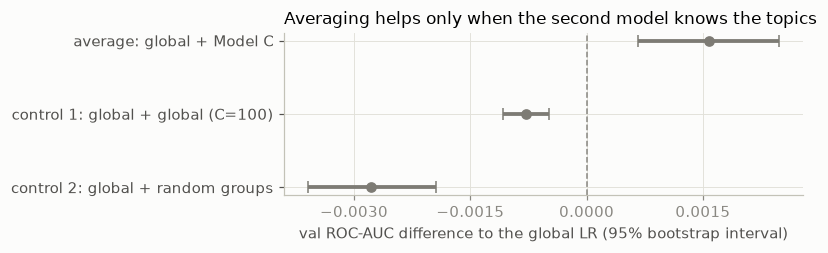

In [12]:
c2 = control.iloc[1:]
fig, ax = plt.subplots(figsize=(7.5, 2.4))
y = np.arange(len(c2))[::-1]
ax.errorbar(c2["gain vs global"], y, xerr=[c2["gain vs global"] - c2["95% CI low"], c2["95% CI high"] - c2["gain vs global"]],
            fmt="o", color=BARS, ecolor=BARS, elinewidth=2.5, capsize=4)   # neutral colour: not about fake/real
ax.axvline(0, color=MUTED, linestyle="--", linewidth=1)
ax.xaxis.set_major_locator(plt.MaxNLocator(5))
ax.set_yticks(y, c2.index); ax.set_xlabel("val ROC-AUC difference to the global LR (95% bootstrap interval)")
ax.set_title("Averaging helps only when the second model knows the topics")
save(fig, "model_c_control"); plt.show()

- **Average:** a small gain (+0.0015 ROC-AUC) whose whole 95% interval lies above zero, so it is not luck of this
  val set.
- **Control 1:** averaging two global models gives no gain (even slightly less), so the gain is not the generic "two
  models are better than one".
- **Control 2:** with random groups instead of topic clusters, the same averaging **hurts**. The only difference to the
  average is that Model C's groups are topics, so **the gain comes from the topics**.

**Conclusion.** Topic-specific classifiers are worse than one global classifier on their own, because each sees less
data and most of the signal is shared across topics. But they capture *something the global model misses* on the topics
they were trained on, and combined with it they give a small, real improvement on seen topics (section 8 shows that
this does not carry over to unseen ones). With the TF-IDF + SVD clusters the same experiment gives a slightly larger
gain (+0.0025).

*Caveat.* K and C were chosen on this same val set, so the gain may be slightly optimistic; the bootstrap interval
covers the sampling of val articles, not the randomness of training. The final test run gives the unbiased number.

## 8. Unseen topics: the cluster split

In the `cluster` split whole topic clusters are held out: val contains Brexit, the Clinton emails/FBI story, North
Korea, the Russia investigation and police shootings; test five other topics (README, "The cluster split"). The models
never saw these topics in training. Comparing `grouped` (topics shared between train and val) with `cluster`
(topics unseen) shows how much each model relies on having seen the topic.

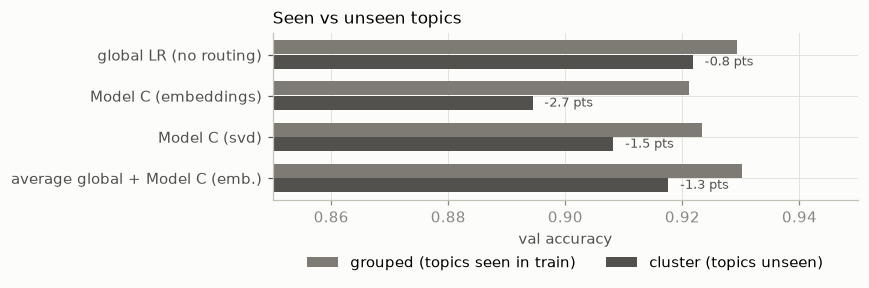

roc_auc                 accuracy                
                                grouped cluster    drop  grouped cluster    drop
global LR (no routing)           0.9794  0.9747  0.0047   0.9293  0.9218  0.0075
Model C (embeddings)             0.9750  0.9619  0.0131   0.9212  0.8944  0.0268
Model C (svd)                    0.9770  0.9692  0.0078   0.9233  0.9082  0.0151
average global + Model C (emb.)  0.9809  0.9742  0.0067   0.9301  0.9176  0.0125

In [13]:
show = {"global LR (no routing)": ("embeddings", "global_lr"), "Model C (embeddings)": ("embeddings", "model_c"),
        "Model C (svd)": ("svd", "model_c"), "average global + Model C (emb.)": ("embeddings", "hybrid_avg")}
unseen = pd.DataFrame({name: {(metric, r): summary[space, r]["val"][m][metric]
                              for metric in ("roc_auc", "accuracy") for r in ("grouped", "cluster")}
                       for name, (space, m) in show.items()}).T
unseen[("roc_auc", "drop")] = unseen[("roc_auc", "grouped")] - unseen[("roc_auc", "cluster")]
unseen[("accuracy", "drop")] = unseen[("accuracy", "grouped")] - unseen[("accuracy", "cluster")]
unseen = unseen[[("roc_auc", "grouped"), ("roc_auc", "cluster"), ("roc_auc", "drop"),
                 ("accuracy", "grouped"), ("accuracy", "cluster"), ("accuracy", "drop")]]

fig, ax = plt.subplots(figsize=(8, 2.9))
y = np.arange(len(unseen))[::-1]
ax.barh(y + 0.18, unseen[("accuracy", "grouped")], height=0.34, color=BARS, label="grouped (topics seen in train)")
ax.barh(y - 0.18, unseen[("accuracy", "cluster")], height=0.34, color=INK2, label="cluster (topics unseen)")
for yi, (a, b) in zip(y, zip(unseen[("accuracy", "grouped")], unseen[("accuracy", "cluster")])):
    ax.text(b + 0.002, yi - 0.18, f"-{100 * (a - b):.1f} pts", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(y, unseen.index); ax.set_xlim(0.85, 0.95); ax.set_xlabel("val accuracy")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2)
ax.set_title("Seen vs unseen topics")
save(fig, "model_c_unseen_topics"); plt.show()
unseen.round(4)

**The global LR hardly suffers on unseen topics**: about 0.005 ROC-AUC and 0.75 accuracy points. What gives fake
articles away in WELFake is mostly wording and style, which carry over to new topics; the cluster shortcut of
section 4 is real, but a word-based classifier does not depend on it.

**Cluster routing suffers clearly more**: 1.5 accuracy points with the SVD clusters and 2.7 with the embedding clusters. An article
from an unseen topic is routed to the nearest *training* topic, whose specialist was trained on different subjects.
Specialisation helps a little on seen topics (the average in section 7) and **hurts on unseen ones**; the small gain of
the average disappears on the `cluster` split.

## 9. Summary and outputs

| Question | Answer (val) |
|---|---|
| Are there topic clusters? | Yes. Embedding clusters are clean topics; TF-IDF + SVD clusters also group by writing style. Both overlap (silhouette ≈ 0.03). |
| Is the cluster a shortcut? | Yes: the cluster alone gives ROC-AUC ≈ 0.71 (embeddings) / 0.75 (SVD) at K = 8, more for larger K. The SVD part includes style. |
| Does cluster routing beat one global classifier? | No: Model C 0.975 (embeddings) / 0.977 (SVD) vs global LR 0.979 on grouped; worse for larger K. |
| Does routing add anything? | On seen topics, combined with the global LR: a small, real gain (+0.0015, confirmed by two controls) that disappears on unseen topics. |
| What happens on unseen topics? | The global LR loses ~0.75 accuracy points; cluster routing loses more (1.5–2.7). |

**Limitations.** Hard assignments on overlapping clusters (low silhouette); K-means prefers similarly sized, round
clusters; results depend on the seed (fixed, `config.SEED`); the SVD clusters mix topic and source style; the
per-cluster probabilities are not calibrated against each other; in the `cluster` split neighbouring topics can stay in
train, so "unseen" means an unseen cluster rather than a subject that never occurs.

| Output | Contents |
|---|---|
| `data/processed/predictions/model_c[_svd]__<regime>.csv` | `doc_id, split, prob_fake` (val + test) |
| `data/processed/predictions/model_c[_svd]__<regime>__clusters.csv` | cluster of every article |
| `reports/model_c/<regime>[__svd]_{tuning,clusters,summary}` | tuning grid, per-cluster table, chosen setting |
| `reports/figures/kmeans_*.png`, `model_c_*.png` | figures of this notebook |

```bash
python scripts/run_model_c.py --regime grouped                     # embeddings: tunes K and C (~40 s)
python scripts/run_model_c.py --regime random                      # same K and C, other split; also --regime cluster
python scripts/run_model_c.py --regime grouped --cluster-on svd    # comparison space
```